## Dataset Preparation - Part 2  

<span style="color:green">

**This notebook corresponds to Step 2 of the data preparation covered in Practical 8 (i.e., `8_2_data_prep_part2.ipynb`). Therefore, in Practical 9, this step can be skipped, and all data can be copied directly from the "processed" folde in practical 8 to the "processed" folder in practicals 9 for downstream tasks.**

</span>

In this notebook, we prepare the dataset by slicing 3D NIfTI images into 2D slices and extracting image slices with their corresponding label masks.  

### Why Work with 2D?  
Since the dataset has a limited number of subjects (just 20), working with 2D slices allows us to increase the amount of data and use simpler 2D models for analysis and training.  

### Workflow  
1. Load NIfTI Files: Read the 3D NIfTI files created in Part 1.  
2. Slice Volumes: Convert 3D images into 2D slices.  
3. Preprocess Slices: Apply basic preprocessing to prepare the data for modeling (e.g., normalization).  
4. Save Slices: Store the 2D slices and masks for downstream tasks.

---

### 1. Import Libraries
Let"s start by importing the necessary libraries.

In [1]:
import os
import shutil
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from scipy.ndimage import zoom

---
### 2. Define Paths
Next, we"ll specify the file paths for loading the dataset.

In [2]:

root_dir = "data/processed"

src_dir = os.path.join(root_dir, "3d_ircadb__nifti_liver")
out_dir = os.path.join(root_dir, "preprocessed_ircadb_liver_dataset")

#### 2.1 Reset output directory

In [3]:
# Reset the output directory to ensure no leftover files
if os.path.exists(out_dir):
    shutil.rmtree(out_dir)

os.makedirs(out_dir, exist_ok=True)

---
### 3. List File Names
We will list all the file names in the directory and filter image and label files.

In [4]:
file_list = os.listdir(src_dir)

image_files = sorted([f for f in file_list if f.endswith("_image.nii.gz")])
label_files = [f.replace("_image.nii.gz", "_mask_liver.nii.gz") for f in image_files]

print("Number of files:", len(image_files))
print(image_files)
print(label_files)

Number of files: 20
['3dircadb1_01_image.nii.gz', '3dircadb1_02_image.nii.gz', '3dircadb1_03_image.nii.gz', '3dircadb1_04_image.nii.gz', '3dircadb1_05_image.nii.gz', '3dircadb1_06_image.nii.gz', '3dircadb1_07_image.nii.gz', '3dircadb1_08_image.nii.gz', '3dircadb1_09_image.nii.gz', '3dircadb1_10_image.nii.gz', '3dircadb1_11_image.nii.gz', '3dircadb1_12_image.nii.gz', '3dircadb1_13_image.nii.gz', '3dircadb1_14_image.nii.gz', '3dircadb1_15_image.nii.gz', '3dircadb1_16_image.nii.gz', '3dircadb1_17_image.nii.gz', '3dircadb1_18_image.nii.gz', '3dircadb1_19_image.nii.gz', '3dircadb1_20_image.nii.gz']
['3dircadb1_01_mask_liver.nii.gz', '3dircadb1_02_mask_liver.nii.gz', '3dircadb1_03_mask_liver.nii.gz', '3dircadb1_04_mask_liver.nii.gz', '3dircadb1_05_mask_liver.nii.gz', '3dircadb1_06_mask_liver.nii.gz', '3dircadb1_07_mask_liver.nii.gz', '3dircadb1_08_mask_liver.nii.gz', '3dircadb1_09_mask_liver.nii.gz', '3dircadb1_10_mask_liver.nii.gz', '3dircadb1_11_mask_liver.nii.gz', '3dircadb1_12_mask_liver

---
### 4. Load and Inspect NIfTI Files
Load an example image and label file to visualize the data structure and metadata (e.g., orientation, shape, spacing).

In [5]:
idx_sample = 0
sample_image_path = os.path.join(src_dir, image_files[idx_sample])
sample_label_path = os.path.join(src_dir, label_files[idx_sample])

image = nib.load(sample_image_path)
label = nib.load(sample_label_path)

In [6]:
def extract_nib_data(img):
    img_arr = img.get_fdata()
    img_shape = img.shape
    img_spacing = img.header.get_zooms()
    img_affine = img.affine
    img_orientation = nib.aff2axcodes(img_affine)
    img_origin = img_affine[:3, 3]

    print(f"Orientation: \n{img_orientation}\n")
    print(f"Shape: \n{img_shape} -> (X, Y, Z)\n")
    print(f"Spacing: \n{img_spacing}\n")
    print(f"Origin: \n{img_origin}\n")
    print(f"Affine matrix: \n{img_affine}\n")

    return img_arr, img_spacing

In [7]:
# Use the function to extract data
img_arr, img_spacing = extract_nib_data(image)

Orientation: 
('L', 'P', 'S')

Shape: 
(512, 512, 129) -> (X, Y, Z)

Spacing: 
(0.57, 0.57, 1.6)

Origin: 
[-0. -0.  0.]

Affine matrix: 
[[-0.56999999 -0.          0.         -0.        ]
 [-0.         -0.56999999  0.         -0.        ]
 [ 0.          0.          1.60000002  0.        ]
 [ 0.          0.          0.          1.        ]]



In [8]:
# Ensure class labels are uint8 (integers) instead of float
mask = label.get_fdata().astype(np.uint8)

print(f"Unique values in mask: {np.unique(mask)}")

Unique values in mask: [0 1]


---
### 5. Visualize Volume
Use a scrollbar widget to visualize the 3D volume along with the mask.

In [ ]:
from plot_utils import scroll_3d_arr_with_mask

# Display the 3D volume interactively.
# Parameters:
# - img_arr: The 3D data array to visualize.
# - mask: The 3D mask array, which overlays on the image
# - voxel_size: spacing (voxel dimensions).
# - cmap: Colormap for displaying slices (default: "gray").
# - dim: The dimension along which to scroll (0, 1, or 2).
# - alpha: transparency control
scroll_3d_arr_with_mask(img_arr, mask, voxel_size=img_spacing, cmap="gray", dim=2, alpha=.2)

interactive(children=(IntSlider(value=64, description='slice_idx', max=128), Output()), _dom_classes=('widget-…

---
### 6. Dataset Inspection
Before preprocessing, we check the details of each image file: orientation, spacing, and shape.

In [10]:
# Iterate through all files and print orientation, spacing, and shape
for file in image_files:
    img = nib.load(os.path.join(src_dir, file))

    img_shape = img.shape
    img_spacing = img.header.get_zooms()
    img_orientation = nib.aff2axcodes(img.affine)

    print(f"File: {file} - Orientation: {img_orientation} - Spacing: {img_spacing} - Shape: {img_shape}")

File: 3dircadb1_01_image.nii.gz - Orientation: ('L', 'P', 'S') - Spacing: (0.57, 0.57, 1.6) - Shape: (512, 512, 129)
File: 3dircadb1_02_image.nii.gz - Orientation: ('L', 'P', 'S') - Spacing: (0.782, 0.782, 1.6) - Shape: (512, 512, 172)
File: 3dircadb1_03_image.nii.gz - Orientation: ('L', 'P', 'S') - Spacing: (0.625, 0.625, 1.25) - Shape: (512, 512, 200)
File: 3dircadb1_04_image.nii.gz - Orientation: ('L', 'P', 'S') - Spacing: (0.742188, 0.742188, 2.0) - Shape: (512, 512, 91)
File: 3dircadb1_05_image.nii.gz - Orientation: ('L', 'P', 'S') - Spacing: (0.782, 0.782, 1.6) - Shape: (512, 512, 139)
File: 3dircadb1_06_image.nii.gz - Orientation: ('L', 'P', 'S') - Spacing: (0.782, 0.782, 1.6) - Shape: (512, 512, 135)
File: 3dircadb1_07_image.nii.gz - Orientation: ('L', 'P', 'S') - Spacing: (0.782, 0.782, 1.6) - Shape: (512, 512, 151)
File: 3dircadb1_08_image.nii.gz - Orientation: ('L', 'P', 'S') - Spacing: (0.561, 0.561, 1.6) - Shape: (512, 512, 124)
File: 3dircadb1_09_image.nii.gz - Orientatio

#### 6.1 Image Inspection Summary

From this inspection, we see that all images have the same orientation, but the spacing is different. Although the in-plane dimensions (X, Y) are the same, we need to resample the volumes to ensure uniform spacing in the XY plane. <br>

Since we are using 2D networks, the Z spacing and slice number (Z) aren't important, as we'll work with 2D slices independently. After resampling, the image shapes will change, so we need to crop or pad them to have a consistent size for input into the network.

**Preprocessing Steps**
1. `Resample` the images and masks.
2. `Crop/Pad` the images and masks.
3. Apply `Normalization`.


---
### 7. Resampling the image
Since we are using 2D networks, the Z spacing is not important. Although we can change it while resampling, in some cases, the space between slices might be large, so we avoid changing the Z spacing to prevent additional interpolation errors. Therefore, we consider `new_spacing = (2.5, 2.5, old_spacing[-1])`. Of course, the X and Y spacing can be set to other values.<br>

Here, we apply resampling to the sample image and mask to give an overview of the process. However, in the following steps, we use this function within an iterative loop to apply it to all samples in the dataset.

In [11]:
def compute_new_shape(old_shape, old_spacing, new_spacing):
    resize_factor = np.array(old_spacing) / np.array(new_spacing)
    new_shape = np.round(old_shape * resize_factor).astype(int)
    return new_shape, resize_factor

old_spacing = image.header.get_zooms()
old_shape = image.shape

new_spacing = (2.5, 2.5, old_spacing[-1])
new_shape, resize_factor = compute_new_shape(old_shape, old_spacing, new_spacing)

print("old_spacing:", old_spacing)
print("old_shape:", old_shape)
print("")
print("new_spacing:", new_spacing)
print("new_shape:", new_shape)

old_spacing: (0.57, 0.57, 1.6)
old_shape: (512, 512, 129)

new_spacing: (2.5, 2.5, 1.6)
new_shape: [117 117 129]


In resampling, the choice of interpolation order is crucial for preserving the characteristics of the image and mask.

- For the `image` (resampled_img), we use `order=2`, which applies a spline interpolation for smoother results, ideal for capturing finer details in continuous data like pixel intensities.

- For the `mask` (resampled_mask), we use `order=0`, which applies nearest-neighbor interpolation. This is important for categorical data like segmentation masks, as it avoids creating non-integer labels and preserves the boundaries between different regions accurately.

In [12]:
resampled_img = zoom(img_arr, resize_factor, order=2)
resampled_mask = zoom(mask, resize_factor, order=0)

print("Resampled image shape:", resampled_img.shape)
print("Resampled mask shape:", resampled_mask.shape)
print(f"Unique values in resampled_mask: {np.unique(resampled_mask)}")

Resampled image shape: (117, 117, 129)
Resampled mask shape: (117, 117, 129)
Unique values in resampled_mask: [0 1]


In [ ]:
scroll_3d_arr_with_mask(resampled_img, resampled_mask, voxel_size=new_spacing, cmap="gray", dim=2, alpha= .2)

interactive(children=(IntSlider(value=64, description='slice_idx', max=128), Output()), _dom_classes=('widget-…

#### 7.1 Image Inspection Summary After Resampling

In this step, we inspect the images to check their orientation, spacing, and shape **after** calculating the new shape for resampling. Note that the actual resampling is not applied here; we are only computing the potential changes.

In [14]:
# Iterate through all files and print orientation, spacing, and shape after resampling
for file in image_files:
    img = nib.load(os.path.join(src_dir, file))

    img_orientation = nib.aff2axcodes(img.affine)

    old_spacing = img.header.get_zooms()
    old_shape = img.shape

    new_spacing = (2.5, 2.5, old_spacing[-1])
    new_shape, resize_factor = compute_new_shape(old_shape, old_spacing, new_spacing)

    print(f"File: {file} - Orientation: {img_orientation} - Spacing: {new_spacing} - Shape: {new_shape}")

File: 3dircadb1_01_image.nii.gz - Orientation: ('L', 'P', 'S') - Spacing: (2.5, 2.5, 1.6) - Shape: [117 117 129]
File: 3dircadb1_02_image.nii.gz - Orientation: ('L', 'P', 'S') - Spacing: (2.5, 2.5, 1.6) - Shape: [160 160 172]
File: 3dircadb1_03_image.nii.gz - Orientation: ('L', 'P', 'S') - Spacing: (2.5, 2.5, 1.25) - Shape: [128 128 200]
File: 3dircadb1_04_image.nii.gz - Orientation: ('L', 'P', 'S') - Spacing: (2.5, 2.5, 2.0) - Shape: [152 152  91]
File: 3dircadb1_05_image.nii.gz - Orientation: ('L', 'P', 'S') - Spacing: (2.5, 2.5, 1.6) - Shape: [160 160 139]
File: 3dircadb1_06_image.nii.gz - Orientation: ('L', 'P', 'S') - Spacing: (2.5, 2.5, 1.6) - Shape: [160 160 135]
File: 3dircadb1_07_image.nii.gz - Orientation: ('L', 'P', 'S') - Spacing: (2.5, 2.5, 1.6) - Shape: [160 160 151]
File: 3dircadb1_08_image.nii.gz - Orientation: ('L', 'P', 'S') - Spacing: (2.5, 2.5, 1.6) - Shape: [115 115 124]
File: 3dircadb1_09_image.nii.gz - Orientation: ('L', 'P', 'S') - Spacing: (2.5, 2.5, 2.0) - Sha

---
### 8. Input Image Dimensions for UNet

In convolutional neural networks like **UNet**, the input image dimensions should be divisible by powers of 2 at each downsampling step. This is because:

- UNet typically uses **pooling layers** or **strides** that halve the dimensions of the image in each step.

To ensure smooth downsampling and upsampling:

- The cropped region should be a **multiple of a specific value** like 128 or 256 (commonly powers of 2).
- If the size is not a multiple of these values, **padding** or **croping** is required, which can introduce artifacts or distortions.

#### 8.1 Padding or Cropping an Image or Mask to a Target Size

This function adjusts an input array (such as an image or mask) to match a target size (here 128x128 is considered) by either padding it with zeros or cropping it to fit the desired dimensions.

- **Padding**: If the input is smaller than the target size, it adds padding symmetrically.
- **Cropping**: If the input is larger than the target size, it crops symmetrically.

In [15]:
### Function to pad or crop an array (image or mask) to a specific size
def pad_or_crop_array(input_array, target_size=(128, 128)):
    current_height, current_width = input_array.shape  # Get the current size
    target_height, target_width = target_size  # The desired size

    ### Padding: If the array is smaller than the target size
    if current_height < target_height or current_width < target_width:
        ### Calculate how much padding is needed
        pad_top = max(0, (target_height - current_height) // 2)
        pad_bottom = max(0, target_height - current_height - pad_top)
        pad_left = max(0, (target_width - current_width) // 2)
        pad_right = max(0, target_width - current_width - pad_left)

        ### Apply padding (filling with zeros)
        input_array = np.pad(input_array, [(pad_top, pad_bottom), (pad_left, pad_right)], mode="constant", constant_values=0)

        ### Update current shape after padding
        current_height, current_width = input_array.shape

    ### Cropping: If the array is still larger than the target size
    if current_height > target_height or current_width > target_width:
        ### Calculate where to crop and ensure no negative indices
        crop_top = max(0, (current_height - target_height) // 2)
        crop_bottom = min(current_height, crop_top + target_height)
        crop_left = max(0, (current_width - target_width) // 2)
        crop_right = min(current_width, crop_left + target_width)

        ### Apply cropping
        input_array = input_array[crop_top:crop_bottom, crop_left:crop_right]

    return input_array

In [16]:
target_size = (128, 128)

sample_slice = resampled_img[:,:,0]

resized_slice = pad_or_crop_array(sample_slice, target_size)

print("slice old shape", sample_slice.shape)
print("slice new shape", resized_slice.shape)

slice old shape (117, 117)
slice new shape (128, 128)


---
### 9. Normalization
Apply min-max normalization to the entire image before cropping or padding to capture the full intensity range. <br>
Normalization is done **per subject**, converting values into the 0-1 range using the formula:

$$X_s = \frac{X - \min(X)}{\max(X) - \min(X)}$$

In [17]:
def min_max_normalize(data):
    return (data - np.min(data)) / (np.max(data) - np.min(data))

---
### 10. Train-Test Split

Before applying preprocessing, we need to **split the data** into **train** and **validation** sets. This allows us to evaluate the model's performance during training.


In [18]:
from sklearn.model_selection import train_test_split

# Split the filtered files into training and validation sets
train_files, val_files = train_test_split(image_files, test_size=0.2, random_state=123456)

# Output the lengths of the training and validation sets
print(f"Number of training files: {len(train_files)}")
print(f"Number of validation files: {len(val_files)}")

print("train_files: ", train_files)
print("val_files: ", val_files)

Number of training files: 16
Number of validation files: 4
train_files:  ['3dircadb1_06_image.nii.gz', '3dircadb1_07_image.nii.gz', '3dircadb1_03_image.nii.gz', '3dircadb1_04_image.nii.gz', '3dircadb1_19_image.nii.gz', '3dircadb1_09_image.nii.gz', '3dircadb1_05_image.nii.gz', '3dircadb1_08_image.nii.gz', '3dircadb1_01_image.nii.gz', '3dircadb1_15_image.nii.gz', '3dircadb1_17_image.nii.gz', '3dircadb1_16_image.nii.gz', '3dircadb1_12_image.nii.gz', '3dircadb1_18_image.nii.gz', '3dircadb1_11_image.nii.gz', '3dircadb1_02_image.nii.gz']
val_files:  ['3dircadb1_20_image.nii.gz', '3dircadb1_14_image.nii.gz', '3dircadb1_13_image.nii.gz', '3dircadb1_10_image.nii.gz']


---
### 11. Applying Preprocessing

Here, we apply **resample**, **normalization** and **pad/crop**. 

- This task is performed on a **slice level (2D)** rather than a subject level (3D).
- To reduce computational cost, we store the preprocessed data as **npy files** of 2D slices.
- Reading a single slice is much faster than loading the complete NIfTI file each time.


In [19]:
for idx_sub in tqdm(range(len(image_files))):
    ### Load the image and label data
    image = nib.load(os.path.join(src_dir, image_files[idx_sub]))
    img_arr = image.get_fdata()
    img_spacing = image.header.get_zooms()

    label = nib.load(os.path.join(src_dir, label_files[idx_sub]))
    mask = label.get_fdata().astype(np.uint8)

    ### Resampling
    new_spacing = (2.5, 2.5, img_spacing[-1])
    resize_factor = np.array(img_spacing) / np.array(new_spacing)

    resampled_img = zoom(img_arr, resize_factor, order=2)
    resampled_mask = zoom(mask, resize_factor, order=0)

    ### Normalization
    normalized_img = min_max_normalize(resampled_img)

    ### Determine the output subdirectory based on the training/validation split
    if image_files[idx_sub] in train_files:
        sub_path = os.path.join(out_dir, "train", f"{idx_sub:02d}")
    else:
        sub_path = os.path.join(out_dir, "val", f"{idx_sub:02d}")

    ### Create directories for images and masks
    image_sub_path = os.path.join(sub_path, "image")
    mask_sub_path = os.path.join(sub_path, "mask")
    os.makedirs(image_sub_path, exist_ok=True)
    os.makedirs(mask_sub_path, exist_ok=True)

    ### Loop over the slices in the volume and save the images and masks
    num_slices = normalized_img.shape[-1]
    for idx_slc in range(num_slices):
        img_slice = normalized_img[:, :, idx_slc]
        mask_slice = resampled_mask[:, :, idx_slc]

        ### Resize
        resized_img_slice = pad_or_crop_array(img_slice, target_size=(128, 128))
        resized_mask_slice = pad_or_crop_array(mask_slice, target_size=(128, 128))

        ### Save the image and mask slices as numpy arrays
        np.save(os.path.join(image_sub_path, f"{idx_sub:02d}_{idx_slc:04d}.npy"), resized_img_slice)
        np.save(os.path.join(mask_sub_path, f"{idx_sub:02d}_{idx_slc:04d}_gt.npy"), resized_mask_slice)

  0%|          | 0/20 [00:00<?, ?it/s]

---
### 12. Validate Preprocessed Data  
Let’s check the saved files to ensure they are correctly preprocessed.  
We will:  
1. Visualize a slice of the image and its mask.  
2. Print basic statistics like the type, shape and range of both the image and the mask.  


In [20]:
# File to check
slice_name = "00_0100.npy"

# Load the image slice and corresponding mask
img_slice = np.load(os.path.join(out_dir, "train", "00", "image", slice_name))
mask_slice = np.load(os.path.join(out_dir, "train", "00", "mask", slice_name.replace(".npy", "_gt.npy")))

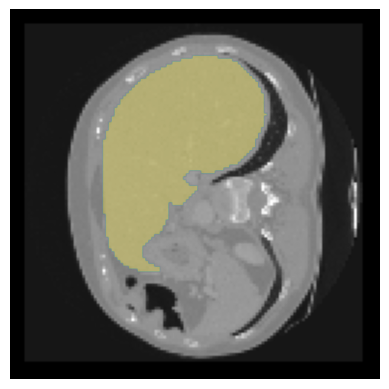

In [21]:
# Visualize the image and mask
plt.figure()
plt.imshow(img_slice, cmap="gray")
plt.imshow(mask_slice, alpha=.3*(mask_slice>0))
plt.axis("off")
plt.show()

In [22]:
# Print statistics for the image and mask
print(f"Image: Type={img_slice.dtype}, Shape={img_slice.shape} Range=({img_slice.min()}, {img_slice.max()})")
print(f"Mask: Type={mask_slice.dtype}, Shape={mask_slice.shape}, Range=({mask_slice.min()}, {mask_slice.max()})")

Image: Type=float64, Shape=(128, 128) Range=(0.0, 0.982453933656911)
Mask: Type=uint8, Shape=(128, 128), Range=(0, 1)
